# Taller de visualización de datos con Python

Caso: centro de formación. Los datos son completamente sintéticos.

**Activación — mapa de Minard:** la banda se estrecha a lo largo del recorrido; sus colores distinguen avance y retirada; la gráfica inferior agrega temperaturas durante el regreso. El mapa no permite atribuir por sí solo las pérdidas exclusivamente al frío: también harían falta fuentes sobre combates, enfermedades, alimentación y decisiones.

Pregunta del proyecto: **¿qué cursos fortalecer y dónde acompañar a estudiantes?** Este cuaderno entrega siete análisis, conclusiones con cifras, revisión de atípicos, corrección de escala y reporte HTML interactivo.

## 1. Preparación
Elija **una** ruta de carga editando `ORIGEN` en la primera celda (`'csv'` o `'sqlite'`). El resto del cuaderno usa el mismo DataFrame `df`. Las figuras se guardan en `graficos/`.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_theme(style='whitegrid', palette='colorblind')
candidatas = [Path.cwd(), *Path.cwd().parents]
candidatas.extend(p for p in Path.cwd().iterdir() if p.is_dir())
BASE = next((p for p in candidatas
             if (p / 'data' / 'processed' / 'dataset_analitico.csv').is_file()
             and (p / 'database' / 'centro_formacion.db').is_file()), None)
if BASE is None:
    raise FileNotFoundError('No se encontró la carpeta del proyecto con data/ y database/.')
RUTA = BASE / 'data'
GRAFICOS = BASE / 'graficos'
GRAFICOS.mkdir(parents=True, exist_ok=True)
ORIGEN = 'csv'  # Cambie a 'sqlite' para usar la base de datos.
FUENTE = 'dataset_analitico.csv' if ORIGEN == 'csv' else 'tabla dataset_analitico de SQLite'

def finalizar_grafico(fig, nombre):
    fig.text(0.99, 0.006, f'Fuente: {FUENTE} (datos sintéticos)',
             ha='right', va='bottom', fontsize=8, color='#555555')
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    fig.savefig(GRAFICOS / nombre, dpi=160, bbox_inches='tight')
    plt.show()
    plt.close(fig)

### Ruta A. CSV
Ejecute esta celda si desea trabajar con el archivo analítico procesado.

In [2]:
if ORIGEN == 'csv':
    df = pd.read_csv(RUTA / 'processed' / 'dataset_analitico.csv', parse_dates=['fecha'])
    print(f'Fuente: CSV | filas y columnas: {df.shape}')
    display(df.head())

Fuente: CSV | filas y columnas: (360, 24)


,inscripcion_id,estudiante_id,curso_id,fecha,progreso,nota,estado,satisfaccion,nombre,edad,...,curso,categoria,modalidad,duracion_horas,precio,mes,aprobado,valor_hora,ranking_nota,grupo_edad
0,I0001,E062,C08,2026-05-02,76.8,2.8,Finalizado,3,Sara Meza,21,...,Ciberseguridad inicial,Redes,Virtual,30,310000,2026-05,False,10333.33,23,19-22
1,I0002,E063,C04,2026-08-15,100.0,5.0,Finalizado,3,Luis Cardona,24,...,SQL para análisis,Datos,Virtual,28,280000,2026-08,True,10000.00,1,23-26
2,I0003,E096,C01,2026-06-22,87.3,3.2,Finalizado,4,Luis Giraldo,29,...,Python básico,Programación,Presencial,32,260000,2026-06,True,8125.00,19,27-40
3,I0004,E094,C02,2026-02-11,42.8,2.7,Retirado,3,Diego Cano,17,...,Análisis con pandas,Datos,Virtual,36,320000,2026-02,False,8888.89,24,16-18
4,I0005,E054,C03,2026-01-11,89.5,4.0,Activo,4,Nataly Meza,21,...,Visualización de datos,Datos,Híbrida,30,300000,2026-01,True,10000.00,11,19-22


### Ruta B. SQLite
Ejecute esta celda en lugar de la anterior si desea practicar consultas SQL. SQLite no necesita servidor.

In [3]:
if ORIGEN == 'sqlite':
    with sqlite3.connect(BASE / 'database' / 'centro_formacion.db') as conexion:
        tablas = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table' ORDER BY name", conexion)
        df = pd.read_sql_query('SELECT * FROM dataset_analitico', conexion)
    df['fecha'] = pd.to_datetime(df['fecha'])
    print('Tablas disponibles:', ', '.join(tablas['name']))
    print(f'Fuente: SQLite | filas y columnas: {df.shape}')
    display(df.head())
elif ORIGEN != 'csv':
    raise ValueError("ORIGEN debe ser 'csv' o 'sqlite'.")

## 2. Reconocer los datos

In [4]:
print(f'Registros: {len(df):,} | columnas: {df.shape[1]}')
print(f'Filas duplicadas: {df.duplicated().sum()}')
display(df.isna().sum().rename('valores_nulos').to_frame())
display(df.describe(include='all').T)

Registros: 360 | columnas: 24
Filas duplicadas: 0


,valores_nulos
inscripcion_id,0
estudiante_id,0
curso_id,0
fecha,0
progreso,0
nota,0
estado,0
satisfaccion,0
nombre,0
edad,0


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
inscripcion_id,360,360,I0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
estudiante_id,360,116,E088,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
curso_id,360,12,C03,69,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha,360,NaN,NaN,NaN,2026-04-24 22:28:00,2026-01-01 00:00:00,2026-02-24 00:00:00,2026-04-13 00:00:00,2026-06-14 06:00:00,2026-09-24 00:00:00,NaN
progreso,360.0,NaN,NaN,NaN,73.886667,16.1,61.575,75.15,88.625,100.0,18.570054
nota,360.0,NaN,NaN,NaN,3.588889,1.5,3.1,3.6,4.1,5.0,0.762191
estado,360,3,Finalizado,184,NaN,NaN,NaN,NaN,NaN,NaN,NaN
satisfaccion,360.0,NaN,NaN,NaN,3.738889,1.0,3.0,4.0,4.0,5.0,0.806408
nombre,360,86,Laura Meza,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad,360.0,NaN,NaN,NaN,22.119444,16.0,19.0,22.0,24.0,31.0,4.081982


## 1. Comparar demanda — barras horizontales
Pregunta: ¿cuáles son los cinco cursos con más matrículas? **Predicción:** espero que un curso introductorio, como Visualización de datos, aparezca entre los primeros.

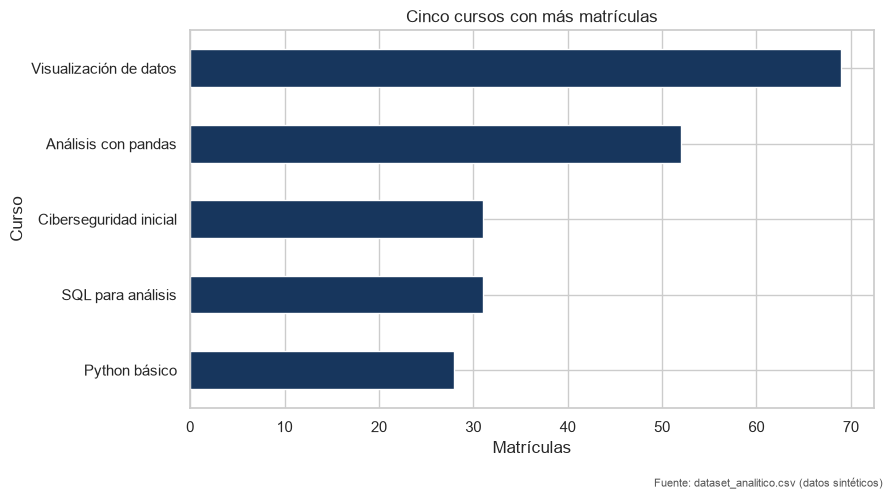

Hallazgo: lidera Visualización de datos con 69 matrículas; el quinto del grupo tiene 28.


In [5]:
conteo_cursos = df['curso'].value_counts().nlargest(5).sort_values()
fig, ax = plt.subplots(figsize=(9, 5))
conteo_cursos.plot.barh(ax=ax, color='#17365D')
ax.set(title='Cinco cursos con más matrículas', xlabel='Matrículas', ylabel='Curso')
finalizar_grafico(fig, '01_top_5_cursos.png')
print(f"Hallazgo: lidera {conteo_cursos.idxmax()} con {conteo_cursos.max()} matrículas; el quinto del grupo tiene {conteo_cursos.min()}.")

## 2. Evolución mensual — líneas
Pregunta: ¿cómo cambian las matrículas por mes? **Predicción:** espero variaciones entre meses, no un crecimiento constante.

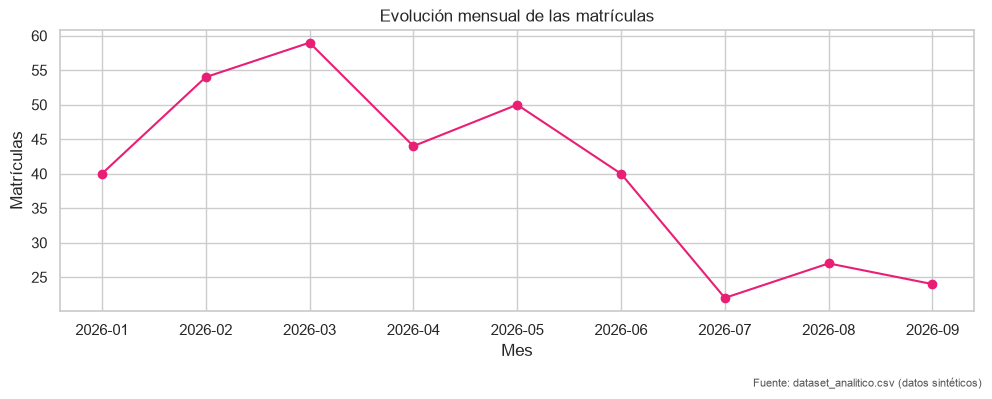

Hallazgo: el máximo observado fue 59 matrículas en 2026-03; describe el periodo disponible, no una causa.


In [6]:
mensual = df.groupby(df['fecha'].dt.to_period('M')).size().sort_index()
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(mensual.index.astype(str), mensual.values, marker='o', color='#E91E75')
ax.set(title='Evolución mensual de las matrículas', xlabel='Mes', ylabel='Matrículas')
finalizar_grafico(fig, '02_matriculas_mensuales.png')
mes_pico = mensual.idxmax()
print(f'Hallazgo: el máximo observado fue {mensual.max()} matrículas en {mes_pico}; describe el periodo disponible, no una causa.')

## 3. Distribuciones — histogramas
Pregunta: ¿cómo se distribuyen las notas y el progreso? **Predicción:** espero que la mayor parte de las notas y del progreso se concentre en valores medios y altos.

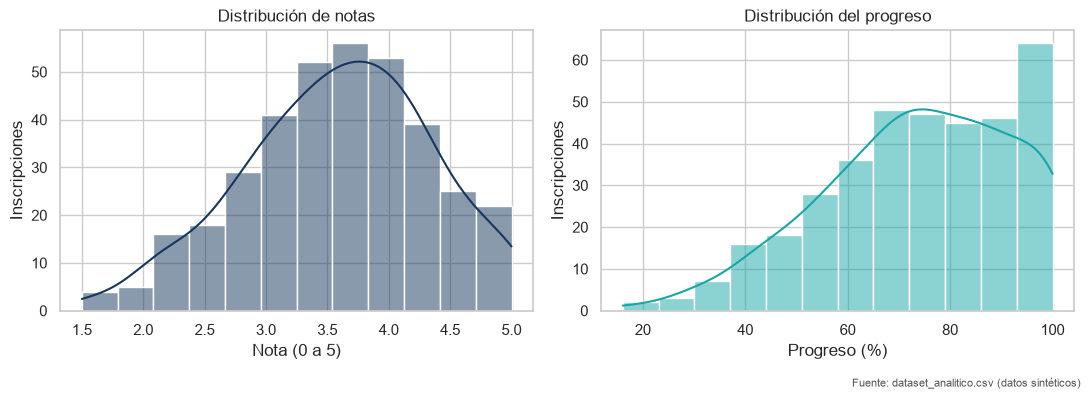

Hallazgo: la mediana de nota es 3.60/5 y la de progreso es 75.2%; revise ambas distribuciones antes de priorizar apoyos.


In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(data=df, x='nota', bins=12, kde=True, color='#17365D', ax=ejes[0])
sns.histplot(data=df, x='progreso', bins=12, kde=True, color='#18A6A6', ax=ejes[1])
ejes[0].set(title='Distribución de notas', xlabel='Nota (0 a 5)', ylabel='Inscripciones')
ejes[1].set(title='Distribución del progreso', xlabel='Progreso (%)', ylabel='Inscripciones')
finalizar_grafico(fig, '03_distribuciones_nota_progreso.png')
print(f"Hallazgo: la mediana de nota es {df['nota'].median():.2f}/5 y la de progreso es {df['progreso'].median():.1f}%; revise ambas distribuciones antes de priorizar apoyos.")

## 4. Comparar notas por modalidad — caja
Pregunta: ¿cambia la mediana o la dispersión entre modalidades? **Predicción:** espero que la mediana más alta corresponda a la modalidad híbrida.

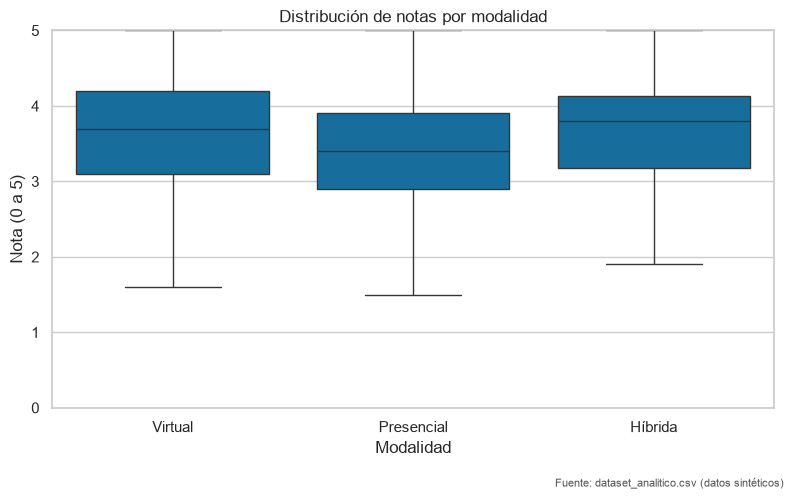

Hallazgo: la mediana más alta corresponde a Híbrida (3.80/5); la caja muestra dispersión, no explica sus causas.


In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x='modalidad', y='nota', ax=ax)
ax.set(title='Distribución de notas por modalidad', xlabel='Modalidad', ylabel='Nota (0 a 5)', ylim=(0, 5))
finalizar_grafico(fig, '04_notas_por_modalidad.png')
medianas = df.groupby('modalidad', observed=True)['nota'].median().sort_values(ascending=False)
print(f'Hallazgo: la mediana más alta corresponde a {medianas.index[0]} ({medianas.iloc[0]:.2f}/5); la caja muestra dispersión, no explica sus causas.')

## 5. Relación progreso–nota — dispersión
Pregunta: ¿progreso y nota se mueven juntos? **Predicción:** espero una asociación positiva; esto no implicaría causalidad.

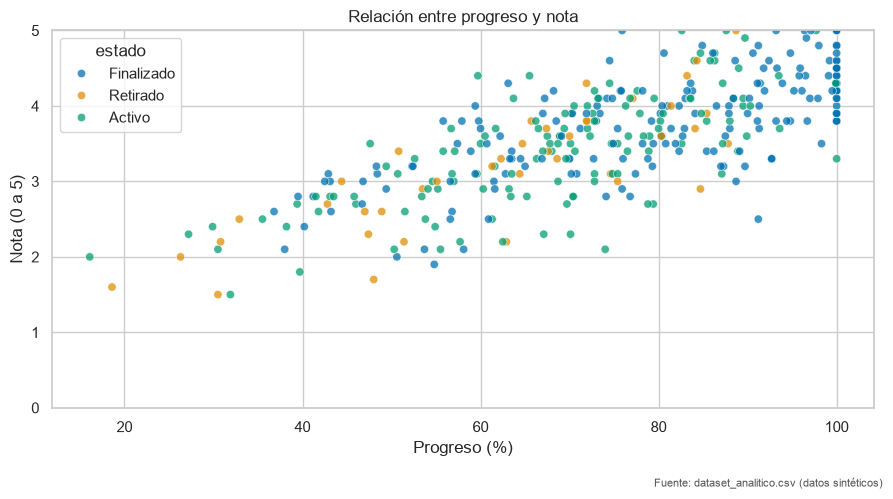

Hallazgo: correlación de Pearson = 0.76; indica asociación lineal y no demuestra causalidad.


In [9]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(data=df, x='progreso', y='nota', hue='estado', alpha=.75, ax=ax)
ax.set(title='Relación entre progreso y nota', xlabel='Progreso (%)', ylabel='Nota (0 a 5)', ylim=(0, 5))
finalizar_grafico(fig, '05_progreso_vs_nota.png')
correlacion = df[['progreso', 'nota']].corr().loc['progreso', 'nota']
print(f'Hallazgo: correlación de Pearson = {correlacion:.2f}; indica asociación lineal y no demuestra causalidad.')

## 6. Correlaciones — mapa de calor
Pregunta: ¿qué par de variables numéricas tiene mayor asociación? **Predicción:** espero que progreso y nota presenten una asociación positiva destacada.

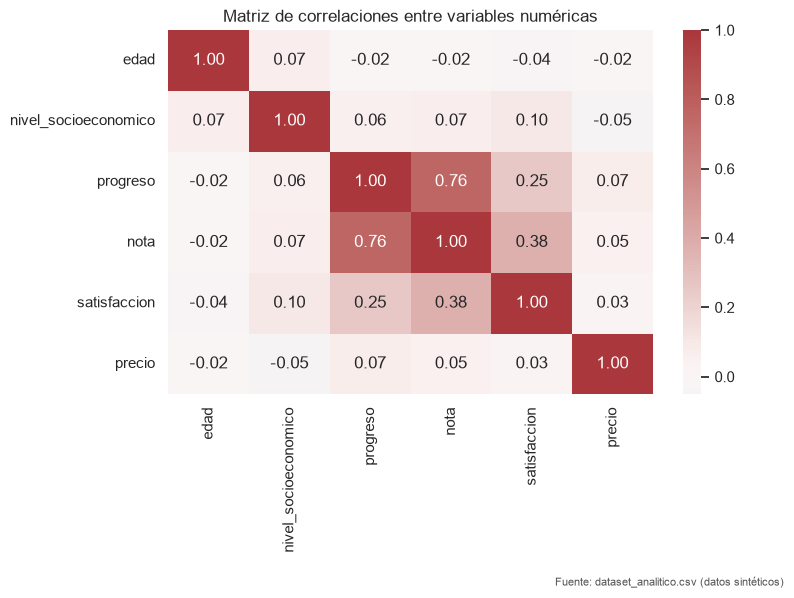

Hallazgo: la asociación de mayor magnitud es progreso–nota (r=0.76); correlación no implica causalidad.


In [10]:
variables = ['edad', 'nivel_socioeconomico', 'progreso', 'nota', 'satisfaccion', 'precio']
matriz_corr = df[variables].corr()
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='vlag', center=0, ax=ax)
ax.set_title('Matriz de correlaciones entre variables numéricas')
finalizar_grafico(fig, '06_matriz_correlaciones.png')
pares = matriz_corr.where(np.triu(np.ones(matriz_corr.shape), k=1).astype(bool)).stack()
par_fuerte = pares.abs().idxmax()
print(f'Hallazgo: la asociación de mayor magnitud es {par_fuerte[0]}–{par_fuerte[1]} (r={pares.loc[par_fuerte]:.2f}); correlación no implica causalidad.')

## 7. Aprobación por curso y modalidad — barras agrupadas
Predicción: espero que la aprobación más baja se concentre en algún curso y que pueda variar entre modalidades. La tasa usa la definición del dataset (`nota >= 3` y `progreso >= 70`).

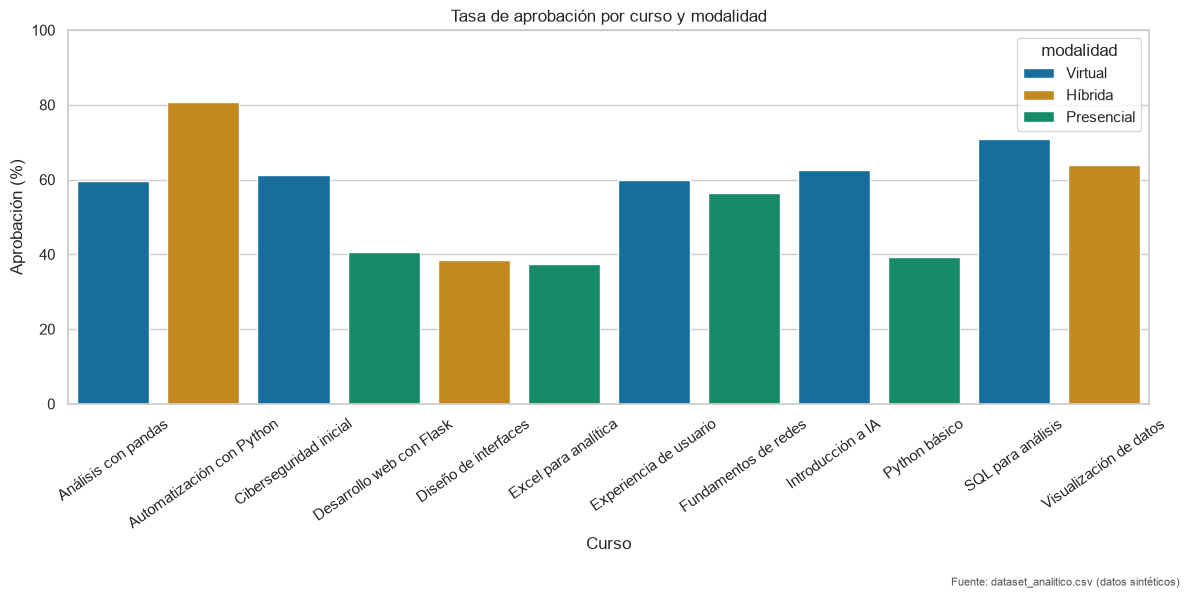

Hallazgo: la menor tasa promedio por curso es Excel para analítica (37.5%); úsela como señal para revisar, no como explicación causal.


In [11]:
aprobacion = (df.groupby(['curso', 'modalidad'], observed=True)['aprobado']
              .mean().mul(100).reset_index(name='tasa_aprobacion'))
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=aprobacion, x='curso', y='tasa_aprobacion', hue='modalidad', ax=ax)
ax.set(title='Tasa de aprobación por curso y modalidad', xlabel='Curso', ylabel='Aprobación (%)', ylim=(0, 100))
ax.tick_params(axis='x', labelrotation=35)
finalizar_grafico(fig, '07_aprobacion_curso_modalidad.png')
resumen_aprobacion = aprobacion.groupby('curso', observed=True)['tasa_aprobacion'].mean().sort_values()
print(f"Hallazgo: la menor tasa promedio por curso es {resumen_aprobacion.index[0]} ({resumen_aprobacion.iloc[0]:.1f}%); úsela como señal para revisar, no como explicación causal.")

## 8. Actividad de cierre
Se revisan valores atípicos con el rango intercuartílico (IQR) y se compara una barra con eje truncado con su versión corregida. Las recomendaciones se imprimen con cifras y lenguaje prudente.

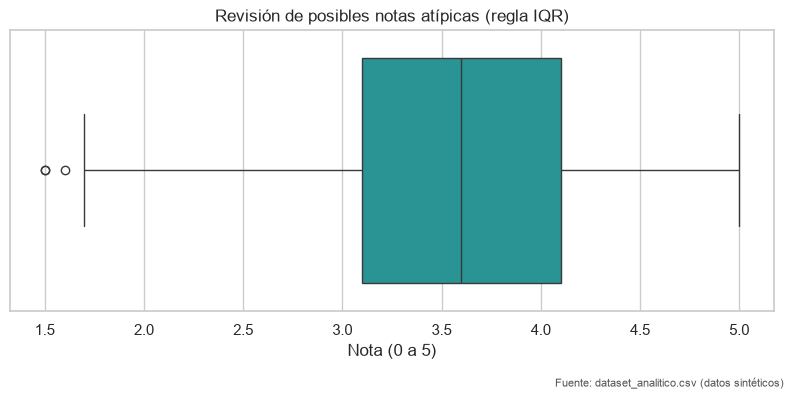

Posibles valores atípicos por IQR: 3 de 360 registros.


,nombre,curso,nota,progreso
23,Samuel Betancur,Python básico,1.5,31.9
208,Samuel García,Fundamentos de redes,1.5,30.5
353,Ana Ruiz,SQL para análisis,1.6,18.6


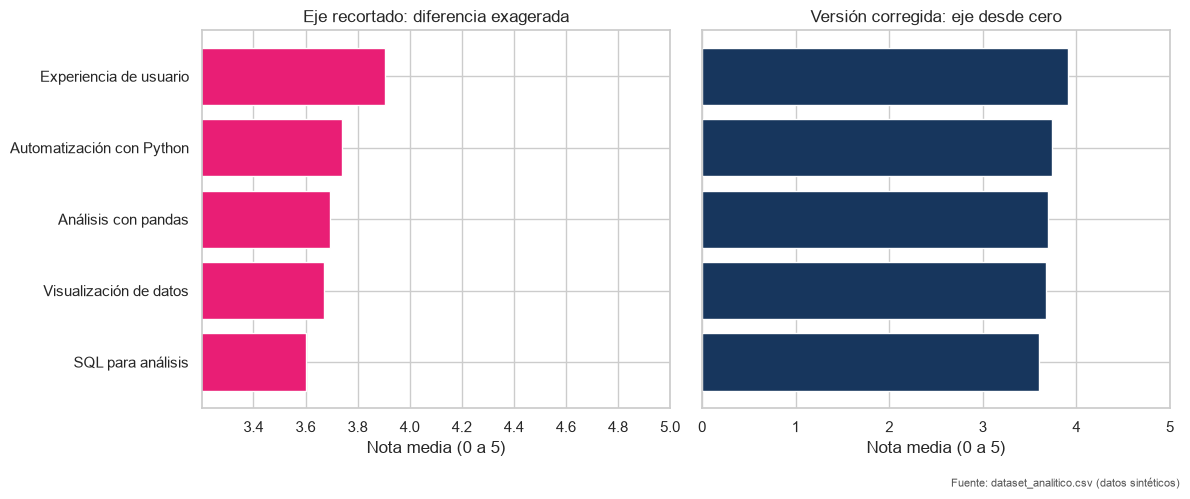

Corrección: para comparar magnitudes con barras, el eje comienza en cero; el panel recortado solo ilustra cómo puede exagerarse la diferencia.
Recomendación 1: revisar capacidad y cupos de Visualización de datos, el curso con más matrículas.
Recomendación 2: analizar necesidades de acompañamiento en Excel para analítica, cuya tasa promedio observada es 37.5%.
Recomendación 3: contrastar progreso, notas y casos IQR con el equipo académico antes de intervenir; estos datos descriptivos no prueban causas.


In [12]:
q1, q3 = df['nota'].quantile([0.25, 0.75])
iqr = q3 - q1
atipicos = df.loc[(df['nota'] < q1 - 1.5 * iqr) | (df['nota'] > q3 + 1.5 * iqr)]
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x='nota', color='#18A6A6', ax=ax)
ax.set(title='Revisión de posibles notas atípicas (regla IQR)', xlabel='Nota (0 a 5)')
finalizar_grafico(fig, '08_revision_notas_atipicas.png')
print(f'Posibles valores atípicos por IQR: {len(atipicos)} de {len(df)} registros.')
if atipicos.empty:
    print('No se detectaron notas fuera de los límites IQR; esto no descarta errores de captura.')
else:
    display(atipicos[['nombre', 'curso', 'nota', 'progreso']].sort_values('nota'))

promedios_top = df.groupby('curso', observed=True)['nota'].mean().nlargest(5).sort_values()
fig, ejes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
ejes[0].barh(promedios_top.index, promedios_top.values, color='#E91E75')
ejes[0].set(title='Eje recortado: diferencia exagerada', xlabel='Nota media (0 a 5)', xlim=(max(0, promedios_top.min() - 0.4), 5))
ejes[1].barh(promedios_top.index, promedios_top.values, color='#17365D')
ejes[1].set(title='Versión corregida: eje desde cero', xlabel='Nota media (0 a 5)', xlim=(0, 5))
finalizar_grafico(fig, '09_correccion_eje_truncado.png')
print('Corrección: para comparar magnitudes con barras, el eje comienza en cero; el panel recortado solo ilustra cómo puede exagerarse la diferencia.')

curso_mayor_demanda = df['curso'].value_counts().idxmax()
curso_menor_aprobacion = resumen_aprobacion.index[0]
print(f'Recomendación 1: revisar capacidad y cupos de {curso_mayor_demanda}, el curso con más matrículas.')
print(f'Recomendación 2: analizar necesidades de acompañamiento en {curso_menor_aprobacion}, cuya tasa promedio observada es {resumen_aprobacion.iloc[0]:.1f}%.')
print('Recomendación 3: contrastar progreso, notas y casos IQR con el equipo académico antes de intervenir; estos datos descriptivos no prueban causas.')

### Reporte interactivo con Plotly
El HTML autocontenido queda en `graficos/reporte_interactivo.html`; puede abrirse directamente en un navegador.

In [13]:
fig = px.scatter(df, x='progreso', y='nota', color='estado',
                 hover_data=['nombre', 'curso', 'modalidad'],
                 title='Progreso y nota por estudiante',
                 labels={'progreso': 'Progreso (%)', 'nota': 'Nota (0 a 5)', 'estado': 'Estado'})
fig.update_yaxes(range=[0, 5])
ruta_html = GRAFICOS / 'reporte_interactivo.html'
fig.write_html(ruta_html, include_plotlyjs=True)
print(f'Reporte interactivo guardado en: {ruta_html}')
fig.show()

Reporte interactivo guardado en: C:\Users\USUARIO\Downloads\OneDrive_2026-10-22\Visualizacion Datos\graficos\reporte_interactivo.html


## 9. Respuestas
Clave de respuestas de la guía: **1-B, 2-A, 3-B, 4-C, 5-C, 6-A, 7-B, 8-C, 9-A, 10-A, 11-B, 12-C.**